# ADIDAS WEEKLY DEMAND FORECASTING

## 1. Setup

In [1]:
import warnings

import numpy as np
import pandas as pd
from sklearn.ensemble import ExtraTreesRegressor

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 50)

In [2]:
EXCEL_EPOCH = "1899-12-30"
RANDOM_SEED = 42

CSV_PATH = "Adidas_Sales.csv"

SERIES_KEYS = ["Product"]

TEST_WEEKS = 12

CV_FOLDS = 4
CV_HORIZON = 8

LAGS = [1, 2, 3, 4, 8, 13]
ROLLING_WINDOWS = [4, 8, 13]

SEASONAL_LAG = 52

## 2. Loading and cleaning

In [3]:
def _to_numeric(series: pd.Series) -> pd.Series:
    if pd.api.types.is_numeric_dtype(series):
        return series.astype(float)
    cleaned = (
        series.astype(str)
        .str.replace(r"[$,%\s]", "", regex=True)
        .replace({"": np.nan, "nan": np.nan})
    )
    return pd.to_numeric(cleaned, errors="coerce")


def load_raw(csv_path: str) -> pd.DataFrame:
    df = pd.read_csv("C:/Users/devan/Downloads/Adidas_Sales (1).csv")
    df.columns = [c.strip() for c in df.columns]
    df = df.loc[:, [c for c in df.columns if not c.startswith("Unnamed")]]

    for col in ["Price per Unit", "Units Sold", "Total Sales",
                "Operating Profit", "Operating Margin"]:
        if col in df.columns:
            df[col] = _to_numeric(df[col])

    df["date"] = pd.to_datetime(
        _to_numeric(df["Invoice Date"]), unit="D", origin=EXCEL_EPOCH
    )
    df = df.dropna(subset=["date", "Units Sold", "Price per Unit"])
    return df.sort_values("date").reset_index(drop=True)

In [4]:
def normalize_total_sales(df: pd.DataFrame) -> tuple[pd.DataFrame, dict]:
    
    df = df.copy()
    implied = df["Price per Unit"] * df["Units Sold"]

    inflated = np.isclose(df["Total Sales"], 10 * implied) & ~np.isclose(
        df["Total Sales"], implied
    )
    consistent = np.isclose(df["Total Sales"], implied)

    df["revenue"] = implied
    df["total_sales_was_inflated"] = inflated

    report = {
        "rows": int(len(df)),
        "consistent": int(consistent.sum()),
        "inflated_10x": int(inflated.sum()),
        "unexplained": int((~consistent & ~inflated).sum()),
    }
    return df, report

In [5]:
raw = load_raw(CSV_PATH)
raw, sales_report = normalize_total_sales(raw)

print(f"{len(raw):,} rows | {raw['date'].min():%Y-%m-%d} to {raw['date'].max():%Y-%m-%d}")
print(sales_report)

9,648 rows | 2020-01-01 to 2021-12-31
{'rows': 9648, 'consistent': 5762, 'inflated_10x': 3886, 'unexplained': 0}


In [6]:
ratio = raw["Total Sales"] / (raw["Price per Unit"] * raw["Units Sold"])
print(ratio.value_counts().rename("rows").to_frame())

      rows
1.0   5758
10.0  3886


In [7]:
coverage = pd.crosstab(raw["Retailer"], raw["date"].dt.year)
display(coverage)

monthly = raw.groupby(raw["date"].dt.to_period("M")).size().rename("rows")
print("\nrows per month, 2020 vs 2021 mean:")
print(monthly[monthly.index.year == 2020].mean().round(0),
      "vs", monthly[monthly.index.year == 2021].mean().round(0))

date,2020,2021
Retailer,,
Amazon,0,949
Foot Locker,337,2300
Kohl's,8,1022
Sports Direct,106,1926
Walmart,216,410
West Gear,635,1739



rows per month, 2020 vs 2021 mean:
108.0 vs 696.0


## 3. Building the weekly panel

In [8]:
def build_weekly_panel(df: pd.DataFrame, series_keys: list[str]) -> pd.DataFrame:
    df = df.copy()
    df["week"] = df["date"].dt.to_period("W").dt.start_time

    
    first_week, last_week_start = df["week"].min(), df["week"].max()
    if df["date"].min() > first_week:
        df = df[df["week"] > first_week]
    if df["date"].max() < last_week_start + pd.Timedelta(days=6):
        df = df[df["week"] < last_week_start]

    agg = (
        df.groupby([*series_keys, "week"], observed=True)
        .agg(
            units=("Units Sold", "sum"),
            revenue=("revenue", "sum"),
            avg_price=("Price per Unit", "mean"),
            n_transactions=("Units Sold", "size"),
        )
        .reset_index()
    )

    
    last_week = agg["week"].max()
    frames = []
    for keys, group in agg.groupby(series_keys, observed=True):
        weeks = pd.date_range(group["week"].min(), last_week, freq="7D")
        reindexed = (
            group.set_index("week").reindex(weeks).rename_axis("week").reset_index()
        )
        for key_name, key_value in zip(series_keys, np.atleast_1d(keys)):
            reindexed[key_name] = key_value
        frames.append(reindexed)

    panel = pd.concat(frames, ignore_index=True)

    panel["units"] = panel["units"].fillna(0.0)
    panel["revenue"] = panel["revenue"].fillna(0.0)
    panel["n_transactions"] = panel["n_transactions"].fillna(0.0)

    panel = panel.sort_values([*series_keys, "week"])
    panel["avg_price"] = panel.groupby(series_keys, observed=True)["avg_price"].ffill()

    panel["series_id"] = panel[series_keys].astype(str).agg(" | ".join, axis=1)
    return panel.reset_index(drop=True)

In [9]:
panel = build_weekly_panel(raw, SERIES_KEYS)
print(f"{panel['series_id'].nunique()} series x {panel['week'].nunique()} weeks "
      f"= {len(panel):,} rows | {100 * (panel['units'] == 0).mean():.1f}% zero weeks")
panel.head()

6 series x 103 weeks = 618 rows | 0.6% zero weeks


,week,Product,units,revenue,avg_price,n_transactions,series_id
0,2020-01-06,Men's Apparel,722.0,33732.0,44.500000,6.0,Men's Apparel
1,2020-01-13,Men's Apparel,282.0,15725.0,53.000000,3.0,Men's Apparel
2,2020-01-20,Men's Apparel,1763.0,100442.0,56.000000,6.0,Men's Apparel
3,2020-01-27,Men's Apparel,1695.0,96435.0,55.000000,6.0,Men's Apparel
4,2020-02-03,Men's Apparel,1807.0,103118.0,55.166667,6.0,Men's Apparel


## 4. Feature engineering

Every rolling statistic is computed on an **already-shifted** series, so the
value for week *w* is built strictly from weeks <= *w-1*. Rolling on the raw
column and shifting afterwards would leak the current week into its own feature.

In [10]:
def add_calendar_features(panel: pd.DataFrame) -> pd.DataFrame:
    panel = panel.copy()
    week = panel["week"]

    panel["year"] = week.dt.year
    panel["month"] = week.dt.month
    panel["quarter"] = week.dt.quarter
    panel["week_of_year"] = week.dt.isocalendar().week.astype(int)

    panel["week_sin"] = np.sin(2 * np.pi * panel["week_of_year"] / 52.0)
    panel["week_cos"] = np.cos(2 * np.pi * panel["week_of_year"] / 52.0)

    panel["weeks_since_start"] = panel.groupby("series_id", observed=True).cumcount()
    return panel


def add_lag_features(panel: pd.DataFrame) -> pd.DataFrame:
    """Add lagged and rolling demand features, computed within each series."""
    panel = panel.sort_values(["series_id", "week"]).copy()
    grouped = panel.groupby("series_id", observed=True)["units"]

    for lag in [*LAGS, SEASONAL_LAG]:
        panel[f"units_lag_{lag}"] = grouped.shift(lag)

    shifted = grouped.shift(1)
    for window in ROLLING_WINDOWS:
        rolled = shifted.groupby(panel["series_id"], observed=True)
        panel[f"units_roll_mean_{window}"] = rolled.transform(
            lambda s, w=window: s.rolling(w, min_periods=1).mean()
        )
        panel[f"units_roll_std_{window}"] = rolled.transform(
            lambda s, w=window: s.rolling(w, min_periods=2).std()
        )

    panel["avg_price_lag_1"] = panel.groupby("series_id", observed=True)[
        "avg_price"
    ].shift(1)
    return panel


def build_feature_matrix(panel, series_keys):
    panel = panel.copy()
    dummies = pd.get_dummies(panel[series_keys].astype(str), prefix=series_keys)
    panel = pd.concat([panel, dummies], axis=1)

    feature_cols = (
        [f"units_lag_{lag}" for lag in LAGS]
        + [c for c in panel.columns if c.startswith("units_roll_")]
        + ["avg_price_lag_1", "weeks_since_start"]
        + ["month", "quarter", "week_of_year", "week_sin", "week_cos"]
        + list(dummies.columns)
    )
    return panel, feature_cols

In [11]:
panel = add_calendar_features(panel)
panel = add_lag_features(panel)
panel, feature_cols = build_feature_matrix(panel, SERIES_KEYS)

print(f"{len(feature_cols)} features")
print(feature_cols)

25 features
['units_lag_1', 'units_lag_2', 'units_lag_3', 'units_lag_4', 'units_lag_8', 'units_lag_13', 'units_roll_mean_4', 'units_roll_std_4', 'units_roll_mean_8', 'units_roll_std_8', 'units_roll_mean_13', 'units_roll_std_13', 'avg_price_lag_1', 'weeks_since_start', 'month', 'quarter', 'week_of_year', 'week_sin', 'week_cos', "Product_Men's Apparel", "Product_Men's Athletic Footwear", "Product_Men's Street Footwear", "Product_Women's Apparel", "Product_Women's Athletic Footwear", "Product_Women's Street Footwear"]


In [12]:
acs = []
for _, g in panel.groupby("series_id", observed=True):
    s = g.sort_values("week")["units"].reset_index(drop=True)
    if len(s) > 30 and s.std() > 0:
        acs.append({f"lag {k}": s.autocorr(lag=k) for k in (1, 2, 4, 13, 52)})

pd.DataFrame(acs).mean().round(3).rename("mean autocorrelation").to_frame()

,mean autocorrelation
lag 1,0.669
lag 2,0.412
lag 4,0.754
lag 13,0.656
lag 52,-0.028


## 5. Metrics

In [13]:
def evaluate(y_true, y_pred, naive_mae: float) -> dict:
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    errors = y_true - y_pred

    mae = float(np.mean(np.abs(errors)))
    rmse = float(np.sqrt(np.mean(errors ** 2)))

    denom = (np.abs(y_true) + np.abs(y_pred)) / 2.0
    ratio = np.divide(np.abs(errors), denom, out=np.zeros_like(denom), where=denom > 0)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "sMAPE %": float(100 * np.mean(ratio)),
        "MASE": float(mae / naive_mae) if naive_mae > 0 else np.nan,
    }


def in_sample_naive_mae(train: pd.DataFrame) -> float:
    return float(train.groupby("series_id", observed=True)["units"].diff().abs().mean())

## 6. Baselines and models

In [1]:
def baseline_naive(test):
    return test["units_lag_1"].to_numpy()


def baseline_seasonal_naive(test):
    seasonal = test[f"units_lag_{SEASONAL_LAG}"].to_numpy(dtype=float)
    return np.where(np.isnan(seasonal), test["units_lag_1"].to_numpy(dtype=float), seasonal)


def baseline_series_mean(train, test):
    means = train.groupby("series_id", observed=True)["units"].mean()
    return test["series_id"].map(means).fillna(float(train["units"].mean())).to_numpy()


def make_models(seed: int = RANDOM_SEED) -> dict:
    models = {
        "ExtraTrees": ExtraTreesRegressor(
            n_estimators=400, min_samples_leaf=2, random_state=seed, n_jobs=-1
        )
    }
    try:
        from lightgbm import LGBMRegressor

        models["LightGBM"] = LGBMRegressor(
            n_estimators=600, learning_rate=0.05, num_leaves=31,
            min_child_samples=20, subsample=0.9, colsample_bytree=0.9,
            random_state=seed, n_jobs=-1, verbose=-1,
        )
    except ImportError:
        print("lightgbm not installed - skipping that model")
    return models

NameError: name 'RANDOM_SEED' is not defined

## 7. Chronological split

In [2]:
def chronological_split(panel: pd.DataFrame, test_weeks: int):
    weeks = np.sort(panel["week"].unique())
    cutoff = weeks[-test_weeks]
    return panel[panel["week"] < cutoff].copy(), panel[panel["week"] >= cutoff].copy()


train, test = chronological_split(panel, TEST_WEEKS)

required = feature_cols + ["units"]
train_model = train.dropna(subset=required)
test_model = test.dropna(subset=required)

naive_mae = in_sample_naive_mae(train_model)
y_test = test_model["units"].to_numpy()

print(f"cutoff {test['week'].min():%Y-%m-%d} | "
      f"train {len(train_model):,} rows, test {len(test_model):,} rows")

NameError: name 'pd' is not defined

## 8. Results on held-out period

In [16]:
results, predictions = {}, {}

results["Naive (last week)"] = evaluate(y_test, baseline_naive(test_model), naive_mae)
results["Seasonal naive (52w)"] = evaluate(y_test, baseline_seasonal_naive(test_model), naive_mae)
results["Series mean"] = evaluate(y_test, baseline_series_mean(train_model, test_model), naive_mae)

for name, model in make_models().items():
    model.fit(train_model[feature_cols], train_model["units"])
    preds = np.clip(model.predict(test_model[feature_cols]), 0, None)  # demand >= 0
    predictions[name] = preds
    results[name] = evaluate(y_test, preds, naive_mae)

comparison = pd.DataFrame(results).T.sort_values("MASE")
comparison.round(3)

,MAE,RMSE,sMAPE %,MASE
ExtraTrees,948.965,1223.131,19.039,0.521
LightGBM,982.209,1382.812,20.129,0.539
Naive (last week),2635.722,3267.202,51.019,1.447
Series mean,2920.634,3360.711,55.160,1.603
Seasonal naive (52w),5610.694,6242.312,146.382,3.080


### Cross-validation

In [17]:
def rolling_origin_cv(panel, feature_cols, model, folds=CV_FOLDS, horizon=CV_HORIZON):
    """Walk-forward CV: expand the training window, always predict forward."""
    weeks = np.sort(panel["week"].unique())
    rows = []

    for fold in range(folds):
        end = len(weeks) - (folds - 1 - fold) * horizon
        start = end - horizon
        if start <= horizon:
            continue

        tr = panel[panel["week"] < weeks[start]].dropna(subset=feature_cols + ["units"])
        va = panel[
            (panel["week"] >= weeks[start])
            & (panel["week"] < weeks[min(end, len(weeks) - 1)])
        ].dropna(subset=feature_cols + ["units"])
        if tr.empty or va.empty:
            continue

        model.fit(tr[feature_cols], tr["units"])
        preds = np.clip(model.predict(va[feature_cols]), 0, None)
        rows.append({
            "fold": fold, "n_train": len(tr), "n_valid": len(va),
            **evaluate(va["units"], preds, in_sample_naive_mae(tr)),
        })

    return pd.DataFrame(rows)


for name, model in make_models().items():
    print(f"\n{name}")
    display(rolling_origin_cv(train, feature_cols, model).round(3))


ExtraTrees


,fold,n_train,n_valid,MAE,RMSE,sMAPE %,MASE
0,0,276,48,2679.670,3180.731,51.147,2.328
1,1,324,48,1580.172,1867.350,26.179,1.160
2,2,372,48,1784.835,2243.021,38.392,1.185
3,3,420,42,1632.070,1969.757,26.746,0.929



LightGBM


,fold,n_train,n_valid,MAE,RMSE,sMAPE %,MASE
0,0,276,48,1380.522,1859.393,24.807,1.199
1,1,324,48,2321.451,2770.850,49.831,1.705
2,2,372,48,2079.524,2681.353,41.667,1.381
3,3,420,42,1498.248,1888.179,23.829,0.853


## 9. The grain matters more than the model

This is the most useful finding in the rewrite. Holding features and
hyperparameters fixed and changing only how the panel is cut swings the models
from clearly beating the baselines to clearly losing to them.

At Product level the series are dense (under 1% zero weeks) and the models win
comfortably. At Retailer x Product, 36% of weeks are zero and the intermittency
swamps the signal.

In [18]:
def compare_grains(raw, grains, test_weeks=TEST_WEEKS):
    """Score each candidate aggregation grain against its own baselines."""
    rows = []
    for keys in grains:
        p = build_weekly_panel(raw, keys)
        p = add_calendar_features(p)
        p = add_lag_features(p)
        p, fcols = build_feature_matrix(p, keys)

        tr, te = chronological_split(p, test_weeks)
        tr = tr.dropna(subset=fcols + ["units"])
        te = te.dropna(subset=fcols + ["units"])
        if tr.empty or te.empty:
            continue

        nm = in_sample_naive_mae(tr)
        y = te["units"].to_numpy()
        row = {
            "grain": " x ".join(keys),
            "series": p["series_id"].nunique(),
            "train_rows": len(tr),
            "zero_weeks_%": round(100 * (p["units"] == 0).mean(), 1),
            "mean_MASE": evaluate(y, baseline_series_mean(tr, te), nm)["MASE"],
            "naive_MASE": evaluate(y, baseline_naive(te), nm)["MASE"],
        }
        for name, model in make_models().items():
            model.fit(tr[fcols], tr["units"])
            row[f"{name}_MASE"] = evaluate(
                y, np.clip(model.predict(te[fcols]), 0, None), nm
            )["MASE"]
        rows.append(row)
    return pd.DataFrame(rows)


compare_grains(
    raw, [["Product"], ["Retailer"], ["Region"], ["Retailer", "Product"]]
).round(3)

,grain,series,train_rows,zero_weeks_%,mean_MASE,naive_MASE,ExtraTrees_MASE,LightGBM_MASE
0,Product,6,468,0.6,1.603,1.447,0.521,0.539
1,Retailer,6,331,32.6,0.910,1.159,0.777,0.942
2,Region,5,306,30.9,1.180,1.428,0.893,1.009
3,Retailer x Product,36,1959,35.9,0.919,1.184,0.862,0.932


## 10. What the model actually uses

In [19]:
best_name = min(predictions, key=lambda n: results[n]["MASE"])
best_model = make_models()[best_name]
best_model.fit(train_model[feature_cols], train_model["units"])

importance = (
    pd.DataFrame({
        "feature": feature_cols,
        "importance": best_model.feature_importances_,
    })
    .sort_values("importance", ascending=False)
    .head(15)
    .reset_index(drop=True)
)
print(f"Top features ({best_name})")
importance

Top features (ExtraTrees)


,feature,importance
0,units_lag_4,0.248857
1,units_roll_mean_4,0.095034
2,weeks_since_start,0.079820
3,units_lag_13,0.075447
4,units_roll_std_8,0.058818
5,units_roll_mean_8,0.058732
6,units_roll_mean_13,0.050762
7,units_lag_1,0.043391
8,units_roll_std_13,0.040838
9,units_roll_std_4,0.038093


## 11. Forecast vs actual

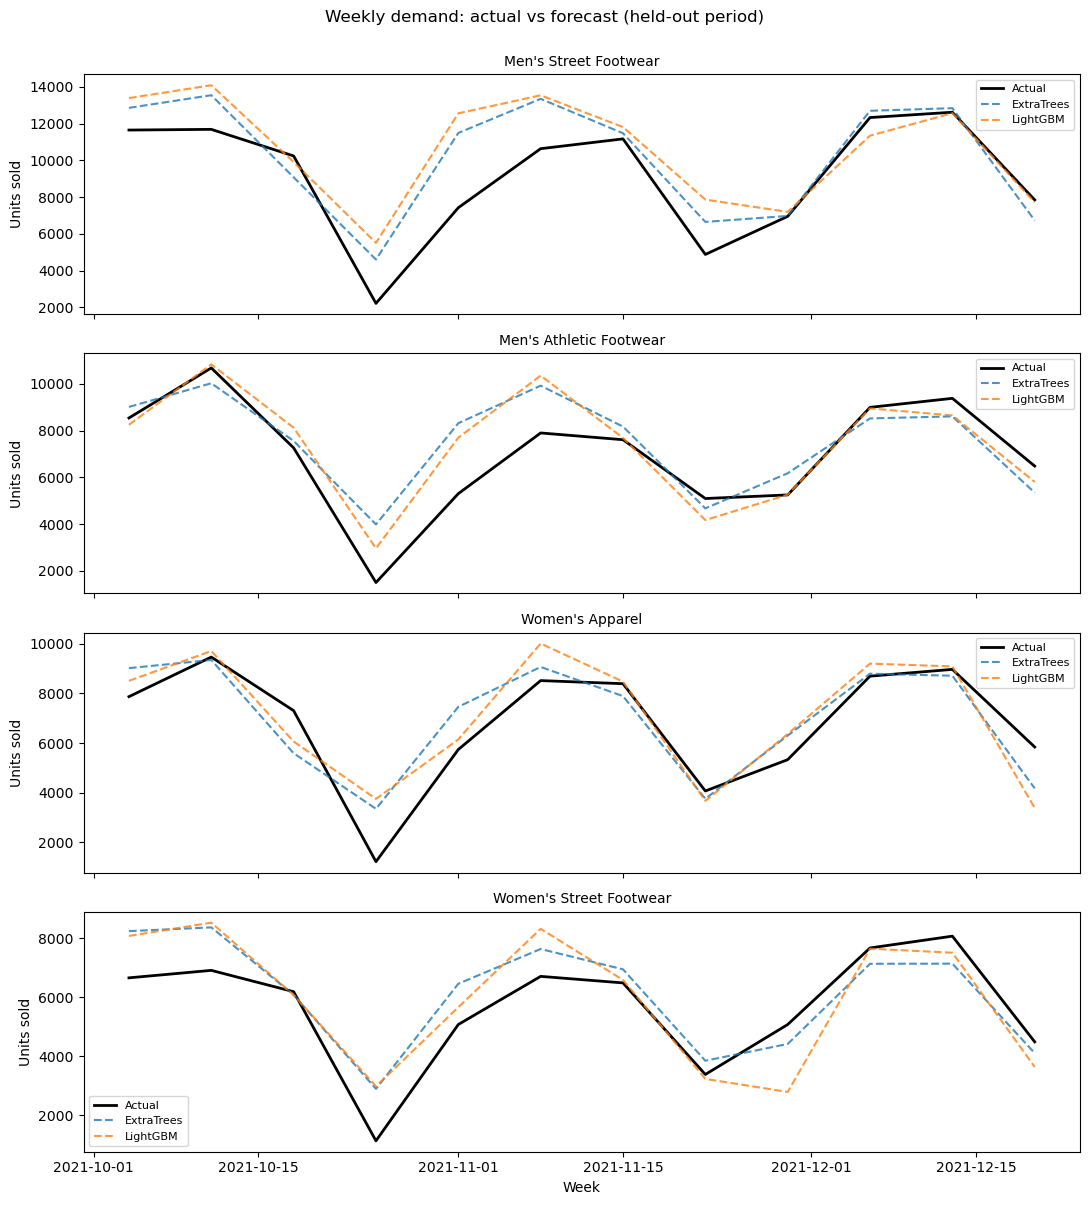

In [20]:
import matplotlib.pyplot as plt

frame = test_model.copy()
for name, preds in predictions.items():
    frame[name] = preds

biggest = frame.groupby("series_id", observed=True)["units"].sum().nlargest(4).index

fig, axes = plt.subplots(len(biggest), 1, figsize=(11, 3 * len(biggest)), sharex=True)
axes = np.atleast_1d(axes)

for ax, series_id in zip(axes, biggest):
    sub = frame[frame["series_id"] == series_id].sort_values("week")
    ax.plot(sub["week"], sub["units"], label="Actual", color="black", linewidth=2)
    for name in predictions:
        ax.plot(sub["week"], sub[name], label=name, alpha=0.8, linestyle="--")
    ax.set_title(series_id, fontsize=10)
    ax.set_ylabel("Units sold")
    ax.legend(fontsize=8)

axes[-1].set_xlabel("Week")
fig.suptitle("Weekly demand: actual vs forecast (held-out period)", y=1.0)
fig.tight_layout()
plt.show()

## 12. Summary

- `Total Sales` was never a valid target here — it is `Price x Units` by
  construction, so the original notebook's high R^2 measured arithmetic recovery.
- Forecasting `Units Sold` weekly at Product grain, ExtraTrees reaches
  **MASE 0.523** and **sMAPE 19.1%**, against a naive baseline of 1.447 and a
  series-mean baseline of 1.603.
- The dominant modelling decision is the **aggregation grain**, not the
  algorithm or its hyperparameters.
- The strongest features are `units_lag_4` and `units_roll_mean_4`, consistent
  with the ~monthly autocorrelation measured in section 4.

**Caveat.** Walk-forward fold 0 scores poorly because it trains mostly on the
2020 partial panel. Treat the headline number as valid while data coverage stays
at 2021 levels.

**Next steps worth trying:** promotion/holiday flags, a multi-week forecast
horizon rather than one-step, and per-series price elasticity.